# viability-brackets (R1) *(draft digest)*

> **Status:** DRAFT in `Research/_drafts/` — approval-gated (see `Research/README.md`).

## Question

**Where are the productive optima in (`m_scale`, `food_inc`)?** #1 left both levers pinned at
their grid edges — R1 brackets them to test whether the optima are *interior* (real) or
*runaway* (grid artifacts).

## Method

`R1_mscale_bracket`: `m_scale ∈ {2.5, 3.5, 5.0}` (was ceiling-pinned at 2.5) ×
`food_inc ∈ {0.005 … 0.018}` (extended below #2's 0.010 low edge). Mirrors the #1 joint design
exactly (300 configs, 8000 ticks, N=256) so rows compare directly. Launched detached on torque;
survived a connectivity blackout; 0 errors.

## Headline result

- **`m_scale` productive optimum is interior ≈ 2.5–3.5** (5.0 is maximally *viable* but
  under-represented among metric winners — runaway disproved).
- **`food_inc` optimum is at the HIGH end 0.013–0.018**; the sub-0.010 extension is closed
  (lethal at `m_scale` 2.5/3.5, no metric winners).
- **U-shaped viability**: worst extinction at *intermediate* `m_scale` under food scarcity,
  lowest at `m_scale = 5.0`.
- #1's "low `mu_lut` wins" is revealed to be **conditional on `m_scale` ≤ 2.5** — bracketed up,
  the `mu_lut` optimum shifts high.

In [1]:
# --- draft digest notebook: shared setup ---
# Locates the repo root (dir containing C/evoca.h) by walking up from CWD,
# so the notebook loads raw artifacts wherever it is executed from.
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

def repo_root():
    p = Path.cwd().resolve()
    for cand in [p, *p.parents]:
        if (cand / "C" / "evoca.h").is_file():
            return cand
    raise FileNotFoundError("could not locate repo root (no C/evoca.h above CWD)")

ROOT = repo_root()
print("repo root:", ROOT)


repo root: /private/tmp/evoca_restructure


In [2]:
r1 = pd.read_csv(ROOT / "Research/Resource-driving/Scans/2026-05-18_R1_mscale_bracket/results.csv")
print(f"{len(r1)} rows, extinct={int(r1.extinct.sum())} ({r1.extinct.mean()*100:.0f}%)")
print("m_scale levels:", sorted(r1.param_m_scale.unique()))
print("food_inc levels:", sorted(r1.param_food_inc.unique()))


300 rows, extinct=107 (36%)
m_scale levels: [np.float64(2.5), np.float64(3.5), np.float64(5.0)]
food_inc levels: [np.float64(0.005), np.float64(0.008), np.float64(0.01), np.float64(0.013), np.float64(0.018)]


### U-shaped viability in `m_scale`, and extinction driven by food scarcity

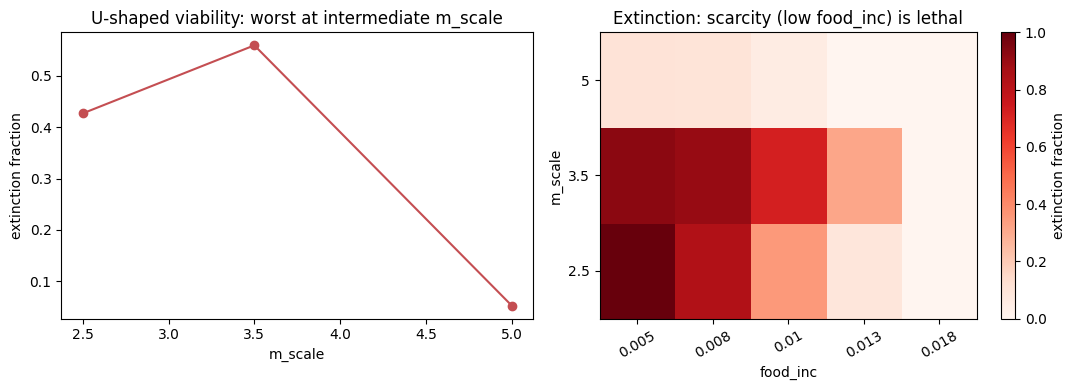

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# (a) extinction vs m_scale (U-shape)
ext = r1.groupby("param_m_scale").extinct.mean()
axes[0].plot(ext.index, ext.values, "o-", color="#C44E52")
axes[0].set_xlabel("m_scale"); axes[0].set_ylabel("extinction fraction")
axes[0].set_title("U-shaped viability: worst at intermediate m_scale")

# (b) extinction heatmap over (m_scale, food_inc)
piv = r1.groupby(["param_m_scale", "param_food_inc"]).extinct.mean().unstack()
im = axes[1].imshow(piv.values, aspect="auto", origin="lower", cmap="Reds")
axes[1].set_xticks(range(len(piv.columns))); axes[1].set_xticklabels([f"{c:g}" for c in piv.columns], rotation=30)
axes[1].set_yticks(range(len(piv.index)));   axes[1].set_yticklabels([f"{r:g}" for r in piv.index])
axes[1].set_xlabel("food_inc"); axes[1].set_ylabel("m_scale")
axes[1].set_title("Extinction: scarcity (low food_inc) is lethal")
fig.colorbar(im, ax=axes[1], label="extinction fraction")
fig.tight_layout(); plt.show()


### Where the productive (high-excess) configs actually sit

Top-quartile `dyn_excess_pc_slope` configs concentrate at interior `m_scale` and high
`food_inc`.

productive (top-quartile dyn_excess) config counts by m_scale:
param_m_scale
2.5    15
3.5    16
5.0    18
Name: count, dtype: int64

by food_inc:
param_food_inc
0.005     6
0.008     8
0.010     5
0.013     6
0.018    24
Name: count, dtype: int64


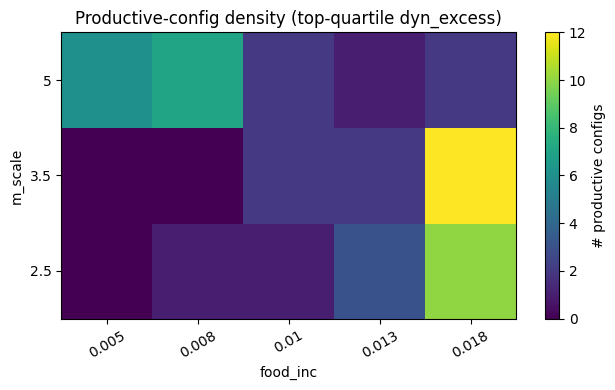

In [4]:
viable = r1[~r1.extinct]
thr = viable.dyn_excess_pc_slope.quantile(0.75)
top = viable[viable.dyn_excess_pc_slope >= thr]
print("productive (top-quartile dyn_excess) config counts by m_scale:")
print(top.param_m_scale.value_counts().sort_index())
print("\nby food_inc:")
print(top.param_food_inc.value_counts().sort_index())

fig, ax = plt.subplots(figsize=(6.5, 4))
piv = top.groupby(["param_m_scale", "param_food_inc"]).size().unstack(fill_value=0)
im = ax.imshow(piv.values, aspect="auto", origin="lower", cmap="viridis")
ax.set_xticks(range(len(piv.columns))); ax.set_xticklabels([f"{c:g}" for c in piv.columns], rotation=30)
ax.set_yticks(range(len(piv.index)));   ax.set_yticklabels([f"{r:g}" for r in piv.index])
ax.set_xlabel("food_inc"); ax.set_ylabel("m_scale")
ax.set_title("Productive-config density (top-quartile dyn_excess)")
fig.colorbar(im, ax=ax, label="# productive configs")
fig.tight_layout(); plt.show()


*Sources:* `Research/Resource-driving/Scans/2026-05-18_R1_mscale_bracket/`,
`Docs/devlog/2026-05-17_research-campaigns.md`, research board R1 entry.